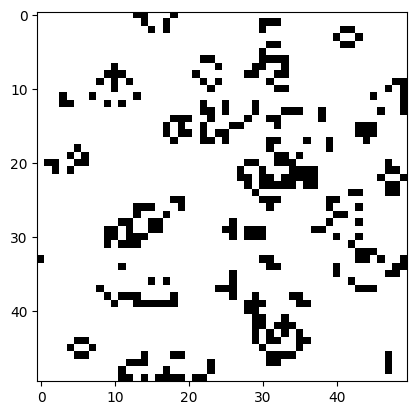

In [6]:
from IPython.display import HTML
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# 初始化参数
N = 50  # 网格大小 N x N
ON, OFF = 1, 0
vals = [ON, OFF]

# 随机生成初始状态
grid = np.random.choice(vals, N*N, p=[0.2, 0.8]).reshape(N, N)

def update(frameNum, img, grid, N):
    # 复制旧网格
    newGrid = grid.copy()
    for i in range(N):
        for j in range(N):
            # 计算 (i,j) 周围 8 个邻居的总和
            total = int((
                grid[i, (j-1)%N] + grid[i, (j+1)%N] +
                grid[(i-1)%N, j] + grid[(i+1)%N, j] +
                grid[(i-1)%N, (j-1)%N] + grid[(i-1)%N, (j+1)%N] +
                grid[(i+1)%N, (j-1)%N] + grid[(i+1)%N, (j+1)%N]
            ) / ON)
            
            # 应用生命游戏规则
            if grid[i, j] == ON:
                if (total < 2) or (total > 3):
                    newGrid[i, j] = OFF
            else:
                if total == 3:
                    newGrid[i, j] = ON
    
    # 更新图像
    img.set_data(newGrid)
    grid[:] = newGrid[:]
    return img,

# 创建动画
fig, ax = plt.subplots()
img = ax.imshow(grid, interpolation='nearest', cmap="gray_r")
ani = animation.FuncAnimation(fig, update, fargs=(img, grid, N,),
                              frames=50, interval=200)
HTML(ani.to_jshtml())

